# Clustering Jerárquico en Machine Learning

**Carlos Francisco Montoya Urzúa**

**Fecha:** 17 de mayo de 2026

**Fuente:** https://www.geeksforgeeks.org/machine-learning/hierarchical-clustering/

---

El **clustering jerárquico** es una técnica de aprendizaje no supervisado que agrupa los datos en una jerarquía de clústeres basándose en la similitud. Construye una estructura en forma de árbol (**dendrograma**) que ayuda a visualizar las relaciones y a decidir el número óptimo de clústeres.

- No requiere seleccionar previamente el número de clústeres.
- Utiliza enfoques aglomerativos o divisivos.
- Comúnmente aplicado en exploración de datos y descubrimiento de patrones.
- Se usa frecuentemente en reconocimiento de patrones, segmentación de clientes y agrupación de imágenes.

Imaginemos que tenemos cuatro frutas con diferentes pesos: una manzana (100 g), un plátano (120 g), una cereza (50 g) y una uva (30 g). El clustering jerárquico empieza tratando cada fruta como su propio grupo.

- Comienza con cada fruta como su propio clúster.
- Se fusionan los elementos más cercanos: la uva (30 g) y la cereza (50 g) se agrupan primero.
- A continuación, la manzana (100 g) y el plátano (120 g) se agrupan.
- Finalmente, estos dos clústeres se fusionan en uno solo.

Al final, todas las frutas se fusionan en un único grupo grande, mostrando cómo el clustering jerárquico combina progresivamente los puntos de datos más similares.

## Dendrograma

Un **dendrograma** es como un árbol genealógico para los clústeres. Muestra cómo los puntos de datos individuales o grupos de datos se van fusionando. En la parte inferior se muestra cada punto de dato como su propio grupo y, a medida que subimos, los grupos similares se van combinando.

Cuanto más bajo sea el punto de fusión, más similares son los grupos. Nos ayuda a ver paso a paso cómo se agrupan las cosas.

- En la parte inferior del dendrograma, los puntos P, Q, R, S y T están todos separados.
- A medida que subimos, los puntos más cercanos se fusionan en un solo grupo.
- Las líneas que conectan los puntos muestran cómo se van fusionando progresivamente en función de su similitud.
- La altura a la que se conectan indica cuán similares son los puntos entre sí; cuanto más corta es la línea, más similares son.

## Tipos de Clustering Jerárquico

Ahora que comprendemos los fundamentos del clustering jerárquico, veamos los dos tipos principales:

1. Clustering Aglomerativo
2. Clustering Divisivo

## 1. Clustering Jerárquico Aglomerativo

También se conoce como **enfoque ascendente** (*bottom-up*) o clustering jerárquico aglomerativo (HAC, por sus siglas en inglés). Los algoritmos ascendentes tratan cada dato como un clúster unitario al inicio, y luego van fusionando sucesivamente pares de clústeres hasta que todos se han unido en un único clúster que contiene todos los datos.

### Flujo de trabajo del Clustering Jerárquico Aglomerativo

1. **Comenzar con puntos individuales:** Cada punto de dato es su propio clúster. Por ejemplo, si tenemos 5 puntos de datos, comenzamos con 5 clústeres, cada uno con un solo punto.
2. **Calcular las distancias entre clústeres:** Se calcula la distancia entre cada par de clústeres. Inicialmente, como cada clúster tiene un punto, esta es la distancia entre dos puntos de datos.
3. **Fusionar los clústeres más cercanos:** Se identifican los dos clústeres con la menor distancia y se fusionan en un único clúster.
4. **Actualizar la matriz de distancias:** Tras la fusión, se tiene un clúster menos. Se recalculan las distancias entre el nuevo clúster y los clústeres restantes.
5. **Repetir los pasos 3 y 4:** Se continúa fusionando los clústeres más cercanos y actualizando la matriz de distancias hasta que quede un único clúster.
6. **Crear un dendrograma:** A medida que avanza el proceso, se puede visualizar la fusión de clústeres usando un diagrama en árbol llamado dendrograma, que muestra la jerarquía de cómo se fusionan los clústeres.

### Implementación

Veamos la implementación del Clustering Aglomerativo:

- Comienza con cada punto de dato como su propio clúster.
- Calcula las distancias entre todos los clústeres.
- Fusiona los dos clústeres más cercanos según un método de enlace.
- Actualiza las distancias para reflejar el nuevo clúster.
- Repite la fusión hasta alcanzar el número deseado de clústeres o hasta que quede uno solo.
- El dendrograma visualiza estas fusiones como un árbol, mostrando las relaciones y distancias entre clústeres.

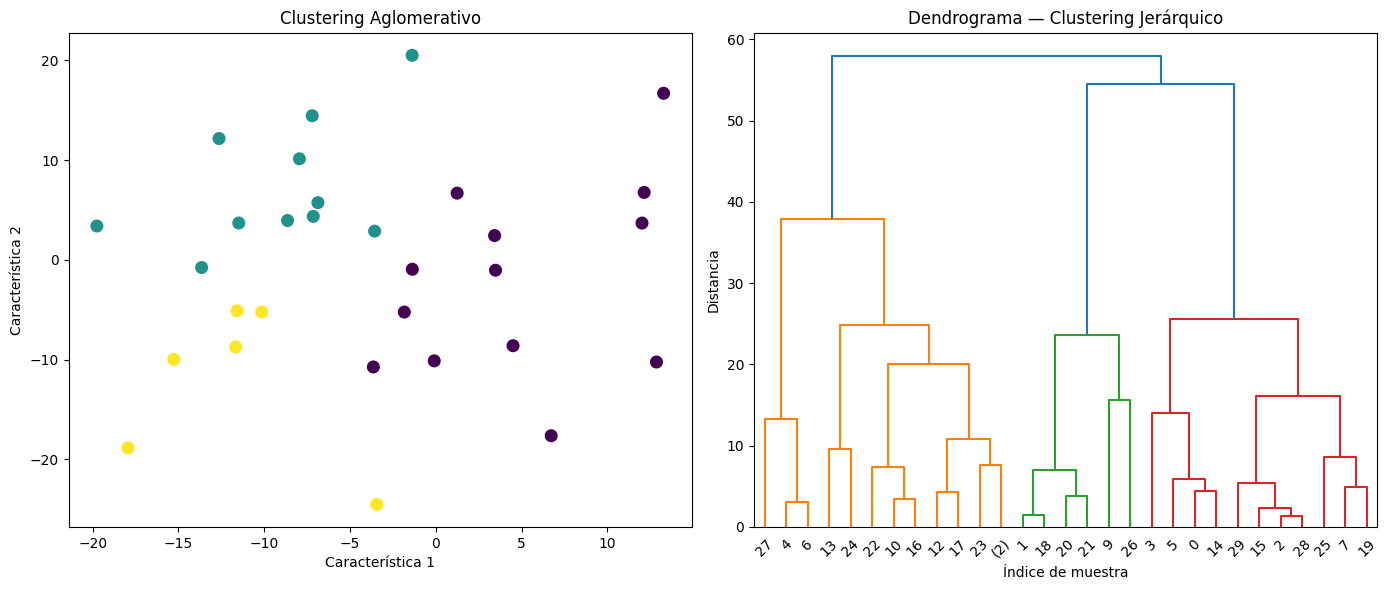

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=30, centers=3, cluster_std=10, random_state=42)

clustering = AgglomerativeClustering(n_clusters=3)
labels = clustering.fit_predict(X)

agg = AgglomerativeClustering(distance_threshold=0, n_clusters=None)
agg.fit(X)


def plot_dendrogram(model, **kwargs):
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)

    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]).astype(float)
    dendrogram(linkage_matrix, **kwargs)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=70)
ax1.set_title("Clustering Aglomerativo")
ax1.set_xlabel("Característica 1")
ax1.set_ylabel("Característica 2")

plt.sca(ax2)
plot_dendrogram(agg, truncate_mode='level', p=5)
plt.title("Dendrograma — Clustering Jerárquico")
plt.xlabel("Índice de muestra")
plt.ylabel("Distancia")

plt.tight_layout()
plt.show()

**Salida:** El gráfico izquierdo muestra los puntos de datos coloreados según el clúster asignado por el algoritmo aglomerativo. El gráfico derecho muestra el dendrograma con la jerarquía de fusiones.

##Ejemplo con otros datos

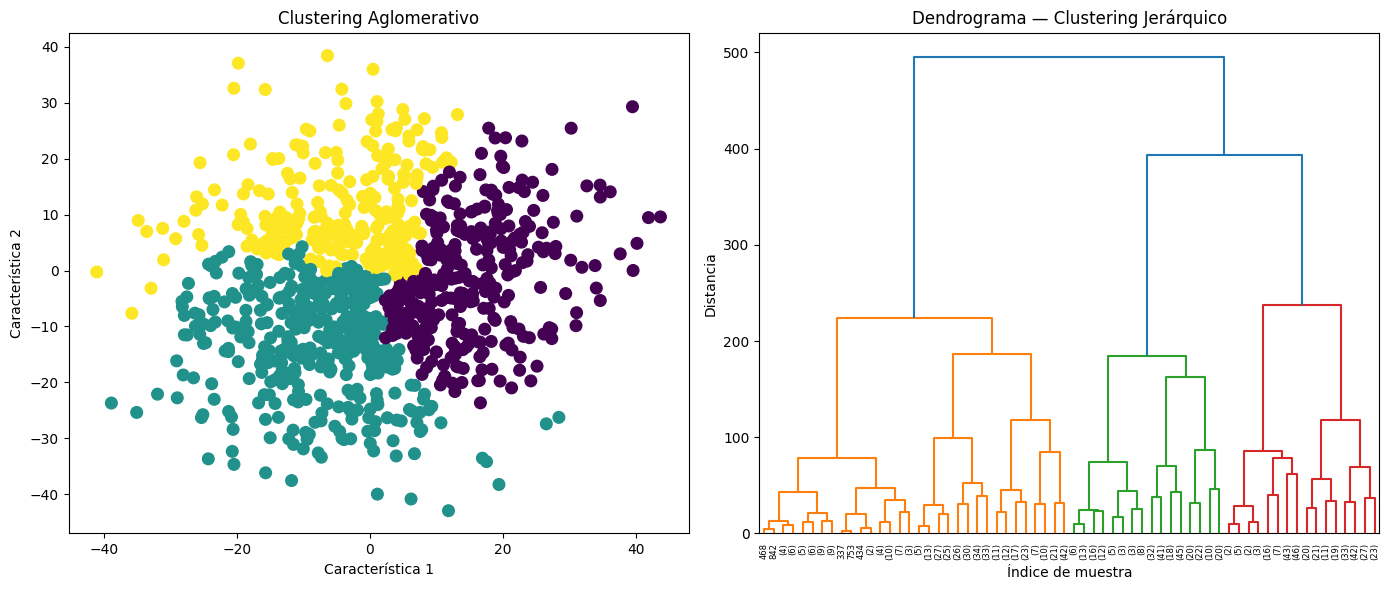

In [2]:
X, _ = make_blobs(n_samples=1000, centers=5, cluster_std=13, random_state=420)

clustering = AgglomerativeClustering(n_clusters=3)
labels = clustering.fit_predict(X)

agg = AgglomerativeClustering(distance_threshold=0, n_clusters=None)
agg.fit(X)


def plot_dendrogram(model, **kwargs):
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)

    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]).astype(float)
    dendrogram(linkage_matrix, **kwargs)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=70)
ax1.set_title("Clustering Aglomerativo")
ax1.set_xlabel("Característica 1")
ax1.set_ylabel("Característica 2")

plt.sca(ax2)
plot_dendrogram(agg, truncate_mode='level', p=5)
plt.title("Dendrograma — Clustering Jerárquico")
plt.xlabel("Índice de muestra")
plt.ylabel("Distancia")

plt.tight_layout()
plt.show()

## 2. Clustering Jerárquico Divisivo

El clustering divisivo también se conoce como **enfoque descendente** (*top-down*). El clustering descendente requiere un método para dividir un clúster que contiene todos los datos, y procede dividiendo clústeres de forma recursiva hasta que los datos individuales se han dividido en clústeres unitarios.

### Flujo de trabajo del Clustering Jerárquico Divisivo

1. **Comenzar con todos los puntos de datos en un único clúster:** Se trata el conjunto de datos completo como un único clúster grande.
2. **Dividir el clúster:** Se divide el clúster en dos clústeres más pequeños. La división se hace típicamente encontrando los dos puntos más disímiles del clúster y usándolos para separar los datos en dos partes.
3. **Repetir el proceso:** Para cada uno de los nuevos clústeres, se repite el proceso de división: se elige el clúster con los puntos más disímiles y se vuelve a dividir en dos clústeres más pequeños.
4. **Detenerse cuando cada punto de dato esté en su propio clúster:** Se continúa el proceso hasta que cada punto de dato sea su propio clúster o se cumpla la condición de parada (como un número predefinido de clústeres).

### Implementación

Veamos la implementación del Clustering Divisivo:

- Comienza con todos los puntos de datos como un único clúster grande.
- Encuentra el clúster más grande y lo divide en dos usando KMeans.
- Repite la división del clúster más grande hasta alcanzar el número deseado de clústeres.
- Asigna etiquetas de clúster a cada punto de dato basándose en las divisiones.
- Devuelve el historial de clústeres en cada paso y las etiquetas finales.
- Visualiza los puntos de datos coloreados por su clúster final.

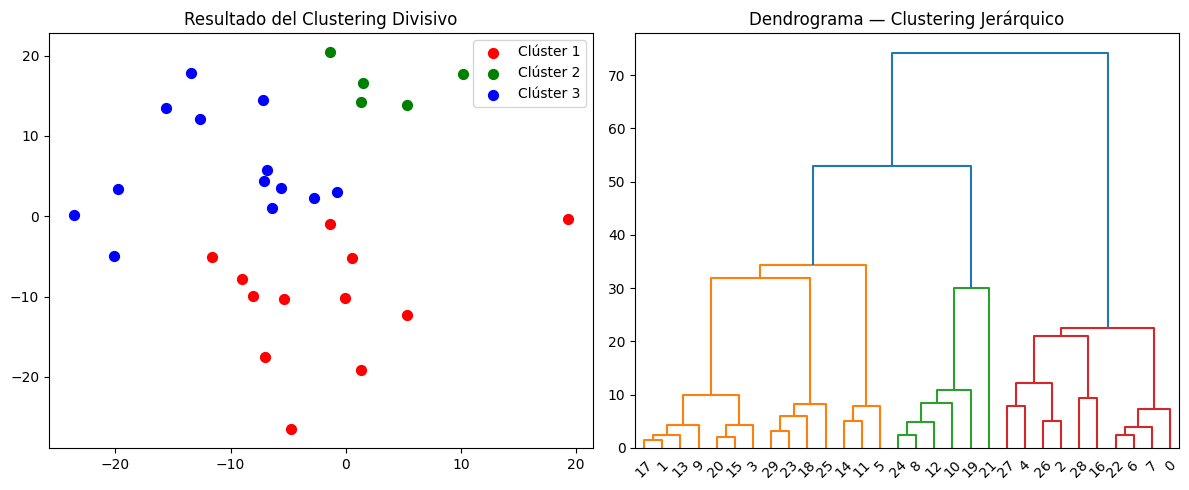

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from scipy.cluster.hierarchy import dendrogram, linkage

X, _ = make_blobs(n_samples=30, centers=5, cluster_std=10, random_state=42)


def divisive_clustering(data, max_clusters=3):
    clusters = [data]
    while len(clusters) < max_clusters:
        cluster_to_split = max(clusters, key=lambda x: len(x))
        clusters.remove(cluster_to_split)

        kmeans = KMeans(n_clusters=2, random_state=42).fit(cluster_to_split)
        cluster1 = cluster_to_split[kmeans.labels_ == 0]
        cluster2 = cluster_to_split[kmeans.labels_ == 1]

        clusters.extend([cluster1, cluster2])
    return clusters


clusters = divisive_clustering(X, max_clusters=3)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
colors = ['r', 'g', 'b', 'c', 'm', 'y']
for i, cluster in enumerate(clusters):
    plt.scatter(cluster[:, 0], cluster[:, 1], s=50,
                c=colors[i], label=f'Clúster {i+1}')
plt.title('Resultado del Clustering Divisivo')
plt.legend()

linked = linkage(X, method='ward')

plt.subplot(1, 2, 2)
dendrogram(linked, orientation='top',
           distance_sort='descending', show_leaf_counts=True)
plt.title('Dendrograma — Clustering Jerárquico')

plt.tight_layout()
plt.show()

##Ejemplo con otros datos

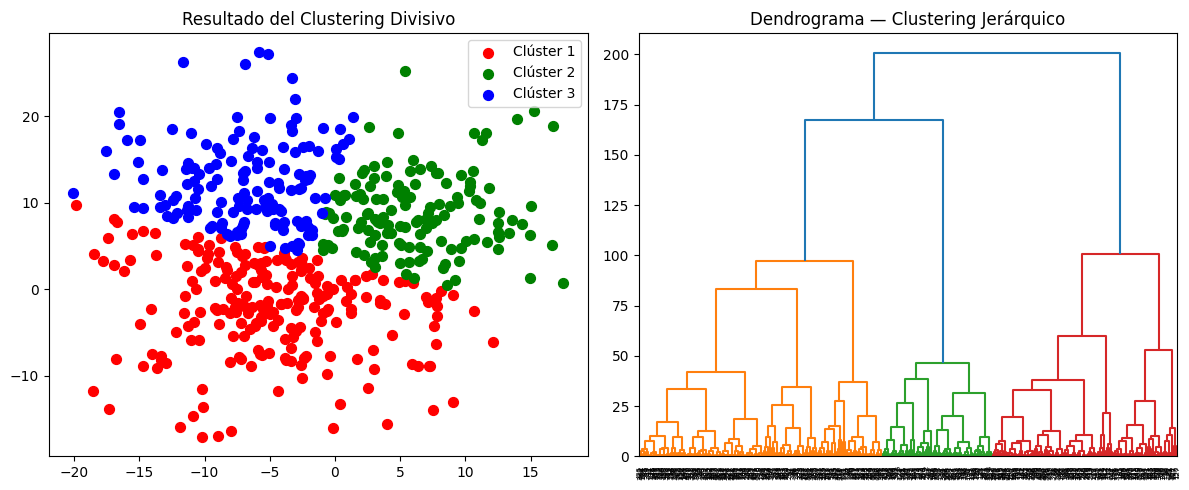

In [4]:
X, _ = make_blobs(n_samples=500, centers=8, cluster_std=6, random_state=225)


clusters = divisive_clustering(X, max_clusters=3)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
colors = ['r', 'g', 'b', 'c', 'm', 'y']
for i, cluster in enumerate(clusters):
    plt.scatter(cluster[:, 0], cluster[:, 1], s=50,
                c=colors[i], label=f'Clúster {i+1}')
plt.title('Resultado del Clustering Divisivo')
plt.legend()

linked = linkage(X, method='ward')

plt.subplot(1, 2, 2)
dendrogram(linked, orientation='top',
           distance_sort='descending', show_leaf_counts=True)
plt.title('Dendrograma — Clustering Jerárquico')

plt.tight_layout()
plt.show()

**Salida:** El gráfico izquierdo muestra el resultado del clustering divisivo con los puntos coloreados por clúster. El gráfico derecho muestra el dendrograma construido con el método de Ward para visualizar la jerarquía de divisiones.

## Cálculo de la Matriz de Distancias

Al fusionar dos clústeres, comprobamos la distancia entre cada par de clústeres y fusionamos el par con la menor distancia / mayor similitud. Pero la pregunta es: ¿cómo se determina esa distancia?

Existen diferentes formas de definir la distancia o similitud entre clústeres (*Inter Cluster Distance/Similarity*). Algunas de ellas son:

- **Distancia Mínima (*Single Linkage*):** Se encuentra la distancia mínima entre dos puntos cualesquiera de los clústeres.
- **Distancia Máxima (*Complete Linkage*):** Se encuentra la distancia máxima entre dos puntos cualesquiera de los clústeres.
- **Promedio de Grupo (*Average Linkage*):** Se calcula la distancia promedio entre todos los pares de puntos de los clústeres.
- **Método de Ward:** La similitud de dos clústeres se basa en el incremento en el error cuadrático cuando se fusionan dos clústeres.

La imagen compara los métodos de distancia entre clústeres:

| Método | Descripción |
|--------|-------------|
| **Mínima** | Usa la distancia más corta entre clústeres |
| **Máxima** | Usa la distancia más larga |
| **Promedio de Grupo** | Calcula la media de todas las distancias por pares |
| **Ward** | Minimiza el incremento en la varianza intra-clúster durante la fusión |